# K-means and Gaussian Mixtures for Stellar Populations

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 11 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

Stars keep the chemical composition of the gas from which they formed, and supernovae change that gas. Massive stars explode soon after they form and release magnesium and some iron. Type Ia supernovae happen much later and release a large amount of iron. They are explosions of white dwarfs in binary systems, where the white dwarf gains mass from a companion. We describe the composition of a star by two logarithmic abundance ratios.

The ratio [X/H] is the base-10 logarithm of the number ratio of the element X to hydrogen, relative to the Sun. The ratio [Mg/Fe] is [Mg/H] minus [Fe/H]. A star with [Fe/H] = -1 has an iron to hydrogen ratio ten times lower than the Sun. A star with a low [Fe/H] is metal-poor, and a star with a high [Fe/H] is metal-rich.

If stars form in bursts, the late explosions add iron between the bursts, so [Mg/Fe] of the gas falls. The next burst forms stars from this gas, with a higher [Fe/H] and a lower [Mg/Fe] than the last burst. Each burst can therefore leave a group of stars in the plane of [Fe/H] and [Mg/Fe]. The gap between two groups can mark a quiet period. [Ting & Ji (2025)](https://ui.adsabs.harvard.edu/abs/2025OJAp....8E...7T/abstract) used mixture models to measure bursty star formation in dwarf galaxies.

Finding groups by eye is subjective, in particular when the groups overlap, so we use clustering algorithms (Chapter 11). K-means puts each star in the cluster of the nearest of $K$ centers. A Gaussian mixture model (GMM) describes the stars as a weighted sum of $K$ Gaussian distributions. It gives each star a probability of belonging to each group. The expectation-maximization (EM) algorithm fits both models. Both need the number of groups $K$.

We build K-means and a GMM from scratch and apply them to an APOGEE sample of stars in the Sculptor dwarf galaxy. We then choose the number of groups with the elbow of the K-means inertia. We also use two information criteria, AIC and BIC, which penalize the number of parameters of the mixture.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Working knowledge of Python, NumPy and matplotlib
- Covariance matrices (Chapter 3)
- The multivariate Gaussian distribution and Bayes' theorem (Chapter 2)
- Maximum likelihood estimation (Chapter 4)

### Learning Objectives

After this tutorial you can do the following.

- Implement K-means and a Gaussian mixture model with the EM algorithm from first principles
- Compare random and K-means++ initialization over many starts
- Follow the convergence of both algorithms over the iterations
- Choose the number of groups with the elbow of the inertia and with the information criteria AIC and BIC
- Fit mixtures from several starts and discard fits with tiny components
- Read groups of objects against a physical hypothesis and judge how far the data support it

We begin by importing the libraries and setting the plot style.

In [1]:
# Import the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.patches as patches
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Fix the random seed
np.random.seed(42)

%matplotlib inline

## The Sculptor Data

The Apache Point Observatory Galactic Evolution Experiment (APOGEE) measured high-resolution spectra of stars in the Sculptor dwarf spheroidal galaxy, a satellite of the Milky Way. Our sample is the APOGEE sample that Ting & Ji (2025) studied. We load the abundances [Fe/H] and [Mg/Fe] of its stars and plot them.

143 stars, [Fe/H] from -2.41 to -0.90, [Mg/Fe] from -0.60 to 0.41


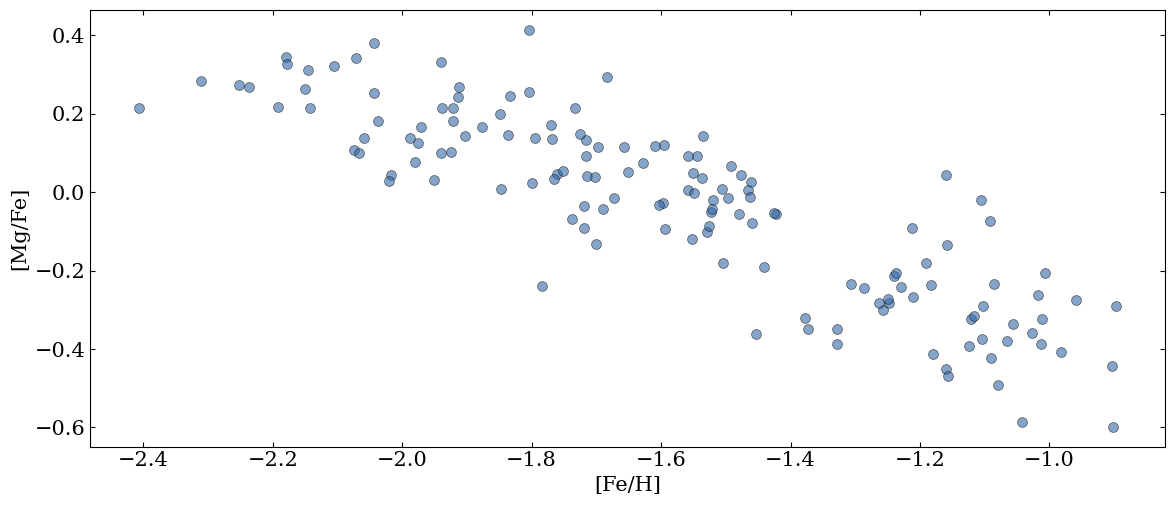

In [2]:
# Load the Sculptor data
data = pd.read_csv("../data/dataset_apogee_sculptor.csv")

# Take the two abundances as a NumPy array
X = data[['FE_H', 'MG_FE']].values

# Print the number of stars and the range of each abundance
print(f"{len(data)} stars, [Fe/H] from {X[:, 0].min():.2f} to {X[:, 0].max():.2f}, "
      f"[Mg/Fe] from {X[:, 1].min():.2f} to {X[:, 1].max():.2f}")

# Plot the stars in the abundance plane
plt.figure(figsize=(12.0, 5.3))
plt.scatter(X[:, 0], X[:, 1], alpha=0.6, s=50, c='C0', edgecolor='k', linewidth=0.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Mg/Fe]')
plt.tight_layout()
plt.show()

[Mg/Fe] falls as [Fe/H] rises, so the stars lie along one band. The density along the band is uneven, and the gaps between possible groups are subtle. We therefore need a rule that we can state and test, and we start with the simplest one, K-means.

## K-means Clustering from Scratch

K-means divides the $N$ stars, with abundance vectors $\mathbf{x}_i$, into $K$ clusters. It minimizes the total squared distance of the stars to the centers of their clusters (Section 11.1)

$$J = \sum_{i=1}^N \sum_{k=1}^K r_{ik} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2,$$

where $r_{ik} \in \{0, 1\}$ is 1 if star $i$ belongs to cluster $k$, and $\boldsymbol{\mu}_k$ is the center of cluster $k$. Each star belongs to one cluster, so $\sum_{k=1}^K r_{ik} = 1$. We call the value of $J$ the inertia (Section 11.3).

A search over all $K^N$ possible assignments is too expensive. If we know the centers, the best assignments are easy. If we know the assignments, the best centers are easy. K-means therefore alternates between two steps (Section 11.2).

The E-step fixes the centers and gives each star to its nearest center. The M-step fixes the assignments and moves each center to the mean of its stars. This is the expectation-maximization (EM) algorithm for K-means. Each step lowers $J$ or leaves it unchanged, so the algorithm stops at a local minimum of $J$, which need not be the lowest value.

K-means uses Euclidean distances, so an abundance with a larger spread weighs more in the distances. The ranges above differ, so [Fe/H] would weigh more. We therefore standardize both abundances to zero mean and unit variance (Section 11.1), so that they count alike.

In [3]:
# Standardize the abundances to zero mean and unit variance
mean_X = np.mean(X, axis=0)
std_X = np.std(X, axis=0)
X_std = (X - mean_X) / std_X

## Initialization Methods for K-means

The start decides which local minimum K-means reaches. A poor start can lead to a poor local minimum or to slow convergence. We implement two initializations.

**Random initialization** picks $K$ different stars at random as the initial centers. The centers can then lie close together in one region of the data.

**K-means++** spreads the initial centers over the data (Section 11.2).

1. Choose the first center uniformly at random from the stars.
2. For each next center, choose a star with a probability proportional to its squared distance from the nearest center chosen so far.
3. Repeat until $K$ centers exist.

A star that is far from all chosen centers has a high probability of becoming the next center. The initial centers therefore tend to lie far apart. K-means++ also has a guarantee (Arthur & Vassilvitskii, 2007). Its expected inertia is within a factor of order $\log K$ of the lowest possible inertia.

We implement both methods.

In [4]:
def init_random(X, k, random_state=None):
    """Pick K data points at random as the initial centers."""
    if random_state is not None:
        np.random.seed(random_state)  # seed the random generator

    # Pick K different data points
    indices = np.random.choice(X.shape[0], k, replace=False)
    return X[indices].copy()

def init_kmeans_plus_plus(X, k, random_state=None):
    """Choose K initial centers with the K-means++ method."""
    if random_state is not None:
        np.random.seed(random_state)  # seed the random generator

    n_samples, n_features = X.shape
    centroids = np.zeros((k, n_features))

    # Choose the first center at random
    first_idx = np.random.choice(n_samples)
    centroids[0] = X[first_idx]

    # Choose the remaining centers
    for c in range(1, k):
        # Squared distance of each point to its nearest chosen center
        min_distances = np.full(n_samples, np.inf)

        for i in range(c):
            distances = np.sum((X - centroids[i])**2, axis=1)
            min_distances = np.minimum(min_distances, distances)

        # Pick the next center with a probability proportional to this squared distance
        probabilities = min_distances / np.sum(min_distances)
        next_idx = np.random.choice(n_samples, p=probabilities)
        centroids[c] = X[next_idx]

    return centroids

## The Expectation-Maximization Algorithm for K-means

We implement the two steps of K-means as functions. The E-step gives star $i$ to the cluster of its nearest center, so $r_{ik} = 1$ for that cluster and $r_{ik} = 0$ for the others. The M-step moves each center to the mean of the set $C_k$ of stars in its cluster (Section 11.2)

$$\boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i.$$

The nearest center gives each star its smallest squared distance. The mean is the point with the smallest total squared distance to the stars of a cluster. This is why each step lowers $J$ or leaves it unchanged. A third function computes the inertia.

In [5]:
def assign_clusters(X, centroids):
    """E-step of K-means. Give each star to its nearest center and return the labels."""

    # Squared Euclidean distance of every star to every center
    distances = np.sum((X[:, None, :] - centroids[None, :, :])**2, axis=2)

    # Take the nearest center
    return np.argmin(distances, axis=1)

def update_centroids(X, labels, centroids):
    """M-step of K-means. Move each center to the mean of its stars. An empty cluster keeps its center."""
    new_centroids = centroids.copy()

    for i in range(len(centroids)):
        # Use the mean of the stars of cluster i as the new center
        if np.any(labels == i):
            new_centroids[i] = np.mean(X[labels == i], axis=0)

    return new_centroids

def compute_inertia(X, labels, centroids):
    """Total squared distance of the stars to the centers of their clusters."""

    # Each star minus the center of its own cluster
    return np.sum((X - centroids[labels])**2)

We now apply one E-step and one M-step to the K-means++ start for $K = 3$. We take $K = 3$, the number that the elbow below favors. We plot the stars in the standardized plane, where K-means measures distances. In the first panel, each star has the color of its nearest start center. In the second panel, arrows lead from the start centers (open circles) to the new centers (crosses).

Inertia after the E-step = 93.59, after the M-step = 56.32


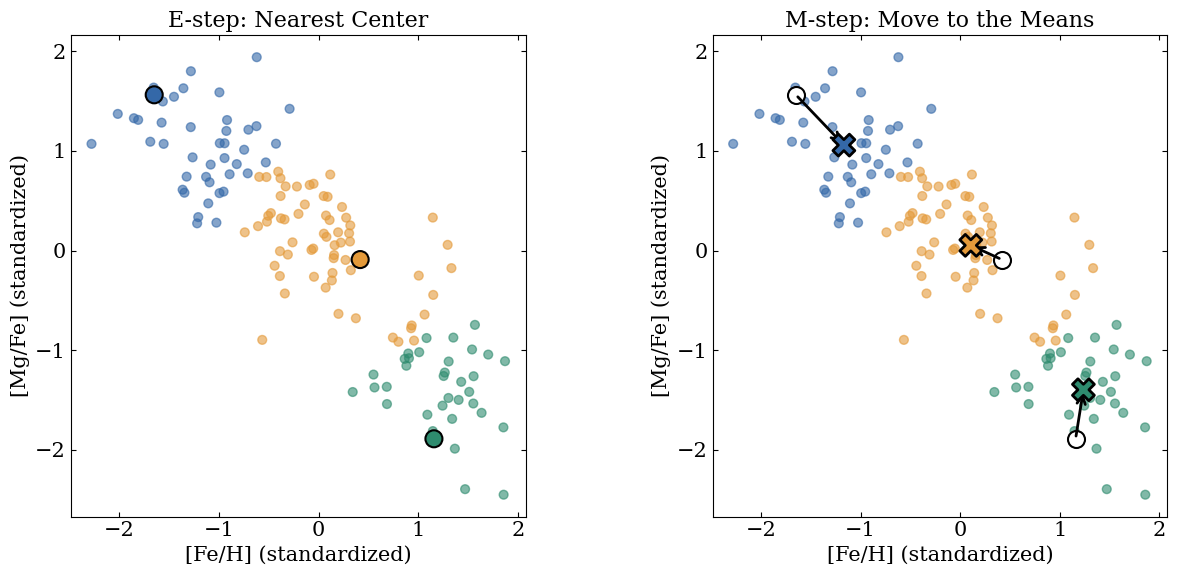

In [6]:
# Start of K-means for K = 3, then one E-step and one M-step
start_centers = init_kmeans_plus_plus(X_std, 3, random_state=42)
start_labels = assign_clusters(X_std, start_centers)
new_centers = update_centroids(X_std, start_labels, start_centers)

# Inertia after the E-step and after the M-step
print(f"Inertia after the E-step = {compute_inertia(X_std, start_labels, start_centers):.2f}, "
      f"after the M-step = {compute_inertia(X_std, start_labels, new_centers):.2f}")

# One color for each cluster, ordered by the [Fe/H] of the start centers
colors = np.array(['C0', 'C1', 'C2'])
rank = np.argsort(np.argsort(start_centers[:, 0]))

fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.0))
for ax in axes:
    # Stars with the color of their nearest start center
    ax.scatter(X_std[:, 0], X_std[:, 1], c=colors[rank[start_labels]], alpha=0.6, s=40)
    ax.set_xlabel('[Fe/H] (standardized)')
    ax.set_ylabel('[Mg/Fe] (standardized)')
    ax.set_aspect('equal')

# First panel, the start centers
axes[0].scatter(start_centers[:, 0], start_centers[:, 1], c=colors[rank], s=150, marker='o', edgecolor='black', linewidth=1.5)
axes[0].set_title('E-step: Nearest Center')

# Second panel, open circles at the start centers, arrows and crosses at the new centers
axes[1].scatter(start_centers[:, 0], start_centers[:, 1], facecolors='white', s=150, marker='o', edgecolor='black', linewidth=1.5, zorder=3)
for old, new in zip(start_centers, new_centers):
    axes[1].annotate('', xy=new, xytext=old, arrowprops=dict(arrowstyle='->', color='black', linewidth=2), zorder=4)
axes[1].scatter(new_centers[:, 0], new_centers[:, 1], c=colors[rank], s=250, marker='X', edgecolor='black', linewidth=2, zorder=5)
axes[1].set_title('M-step: Move to the Means')

plt.tight_layout()
plt.show()

The M-step moves each center to the mean of the stars with its color, and the inertia falls. This is only the first step. The centers keep moving until the algorithm converges.

## The Complete K-means Algorithm

The complete algorithm repeats the E-step and the M-step until the centers stop moving, that is, until their total shift falls below a small tolerance. We store the inertia and the centers of every iteration, to follow the convergence.

We implement the complete algorithm.

In [7]:
def kmeans(X, k, max_iter=100, tol=1e-4, init_method='random', random_state=None):
    """Run K-means. Return the centers, the labels, the inertia, the number of iterations and the history."""

    # Initialize the centers
    if init_method == 'random':
        centroids = init_random(X, k, random_state)
    elif init_method == 'kmeans++':
        centroids = init_kmeans_plus_plus(X, k, random_state)
    else:
        raise ValueError("init_method must be 'random' or 'kmeans++'")

    # Start the history
    history = {'centroids': [centroids.copy()], 'inertia': []}

    # Alternate the E-step and the M-step
    for iteration in range(max_iter):
        # E-step, and the inertia of the current assignment
        labels = assign_clusters(X, centroids)
        history['inertia'].append(compute_inertia(X, labels, centroids))

        # M-step, and the total shift of the centers
        new_centroids = update_centroids(X, labels, centroids)
        centroid_shift = np.sqrt(np.sum((new_centroids - centroids)**2))
        centroids = new_centroids
        history['centroids'].append(centroids.copy())

        # Stop when the centers hardly move
        if centroid_shift < tol:
            break

    # Final assignment and inertia
    labels = assign_clusters(X, centroids)
    return centroids, labels, compute_inertia(X, labels, centroids), iteration + 1, history

We run the complete algorithm for $K = 3$ with both initializations.

In [8]:
# Run K-means with both initializations
random_centroids, random_labels, random_inertia, random_iters, random_history = kmeans(
    X_std, k=3, init_method='random', random_state=42)
kmpp_centroids, kmpp_labels, kmpp_inertia, kmpp_iters, kmpp_history = kmeans(
    X_std, k=3, init_method='kmeans++', random_state=42)

print(f"Random initialization, {random_iters} iterations, inertia = {random_inertia:.2f}")
print(f"K-means++ initialization, {kmpp_iters} iterations, inertia = {kmpp_inertia:.2f}")

# Print the sizes of the clusters of the K-means++ run, sorted
print("Cluster sizes: " + " ".join(str(n) for n in np.sort(np.bincount(kmpp_labels))))

Random initialization, 10 iterations, inertia = 47.26
K-means++ initialization, 6 iterations, inertia = 47.26
Cluster sizes: 45 45 53


We plot the final clusters and the path of each center for both runs. We use the original abundance plane, because the standardized axes have no physical meaning. Circles mark the initial centers and crosses mark the final centers. The right panel shows the inertia of both runs at each iteration. The first segment of each K-means++ path is the M-step above. The first point of its inertia curve is the inertia after the first E-step.

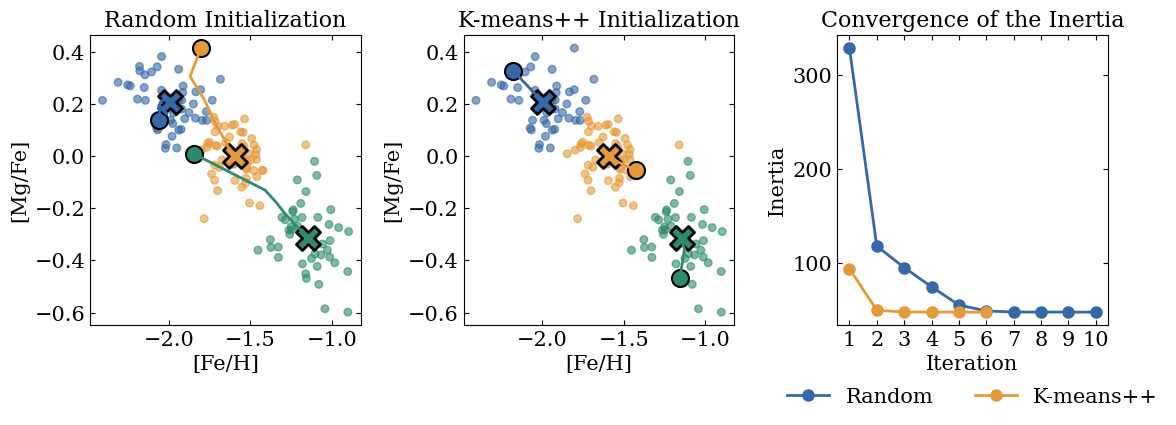

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12.0, 4.6))
runs = [('Random', random_centroids, random_labels, random_history),
        ('K-means++', kmpp_centroids, kmpp_labels, kmpp_history)]

# First two panels, the final clusters and the paths of the centers in the original scale
for ax, (name, centroids, labels, history) in zip(axes[:2], runs):
    # Order the clusters by the [Fe/H] of their centers, so that both runs use the same colors
    rank = np.argsort(np.argsort(centroids[:, 0]))
    ax.scatter(X[:, 0], X[:, 1], c=colors[rank[labels]], alpha=0.6, s=30)

    for i in range(3):
        # Path of center i over the iterations
        path = np.array([c[i] for c in history['centroids']]) * std_X + mean_X
        ax.plot(path[:, 0], path[:, 1], '-', color=colors[rank[i]], linewidth=2)

        # Circle at the start and cross at the end
        ax.scatter(path[0, 0], path[0, 1], c=[colors[rank[i]]], s=150, marker='o',
                   edgecolor='black', linewidth=1.5)
        ax.scatter(path[-1, 0], path[-1, 1], c=[colors[rank[i]]], s=300, marker='X',
                   edgecolor='black', linewidth=2)

    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel('[Mg/Fe]')
    ax.set_title(f'{name} Initialization')

# Third panel, the inertia of both runs
for name, _, _, history in runs:
    axes[2].plot(range(1, len(history['inertia']) + 1), history['inertia'],
                 'o-', linewidth=2, markersize=8, label=name)
axes[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))  # whole iterations only
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Inertia')
axes[2].set_title('Convergence of the Inertia')
axes[2].legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
plt.show()

Both runs end at the same three clusters and the same inertia, and the inertia never rises. The three clusters have similar sizes. In this run, the K-means++ centers start near their final positions, so they move less, and the inertia starts lower. The K-means++ run stops after fewer iterations than the random start.

## Initialization over Many Starts

To compare the initializations, we run K-means from 1000 seeds for each initialization, for $K = 3$ and $K = 6$. For each case we print the lowest inertia, the mean inertia and the mean number of iterations. We also print the share of runs within 1 percent of the lowest inertia that any run reached for that $K$.

In [10]:
print(f"K | {'initialization':<14} | {'lowest':>6} | {'mean':>5} | {'within 1%':>9} | {'iterations':>10}")
for k in (3, 6):
    # Inertia and number of iterations of the runs from 1000 seeds
    runs = {method: np.array([kmeans(X_std, k, init_method=method, random_state=seed)[2:4]
                              for seed in range(1000)])
            for method in ('random', 'kmeans++')}

    # Lowest inertia that any run reached for this K
    lowest = min(r[:, 0].min() for r in runs.values())

    # One line for each initialization
    for method, r in runs.items():
        share = 100 * np.mean(r[:, 0] < 1.01 * lowest)
        print(f"{k} | {method:<14} | {r[:, 0].min():6.2f} | {r[:, 0].mean():5.2f} | {share:8.0f}% | {r[:, 1].mean():10.1f}")

K | initialization | lowest |  mean | within 1% | iterations
3 | random         |  47.26 | 47.30 |      100% |        8.4
3 | kmeans++       |  47.26 | 47.26 |      100% |        7.4
6 | random         |  25.72 | 28.64 |        6% |        9.8
6 | kmeans++       |  25.72 | 27.75 |        9% |        8.7


For $K = 3$ every run of both initializations ends within 1 percent of the lowest inertia. For $K = 6$ the runs differ, and K-means++ gives a lower mean inertia and more runs close to the lowest inertia. A single run can therefore end above the lowest inertia. In practice we run K-means from several starts and keep the run with the lowest inertia, especially for a large $K$ (Section 11.2).

## Selecting the Optimal Number of Clusters

K-means needs the number of clusters $K$ in advance, but we do not know the number of stellar populations in Sculptor. The elbow method looks at how the inertia falls as $K$ grows (Section 11.3). The inertia always falls as $K$ grows, and it is zero for $K = N$. If the data contain groups, we expect a point after which more clusters give little gain. This point is the elbow.

We compute the inertia for $K = 2$ to 9. For each $K$ we run K-means++ from 20 starts and keep the lowest inertia.

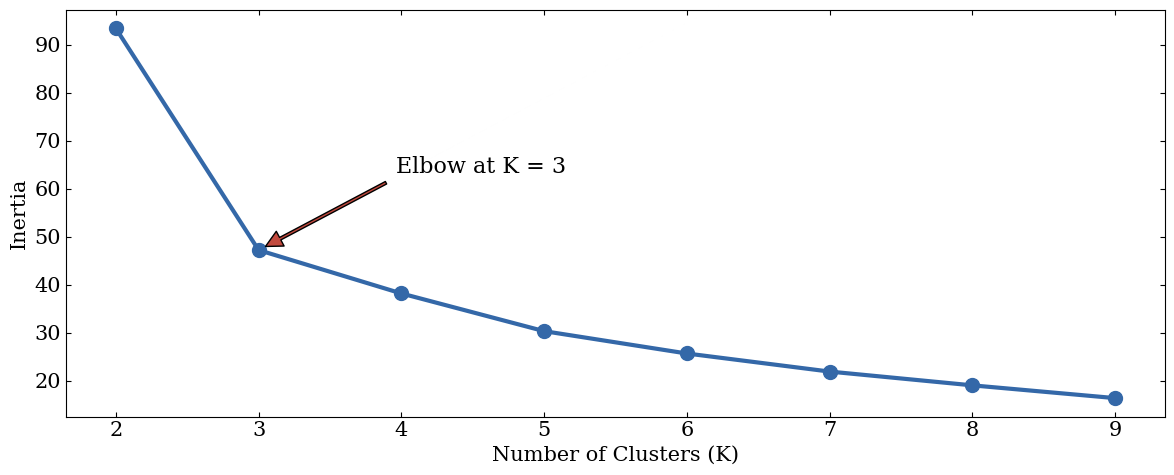

In [11]:
# Lowest inertia of 20 K-means++ starts for each K from 2 to 9
k_range = range(2, 10)
inertias = [min(kmeans(X_std, k, init_method='kmeans++', random_state=seed)[2] for seed in range(20))
            for k in k_range]

# Plot the elbow curve
plt.figure(figsize=(12.0, 5.0))
plt.plot(k_range, inertias, 'o-', linewidth=3, markersize=10)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(k_range)

# Mark the potential elbow, with the text in axes coordinates
plt.annotate('Elbow at K = 3', xy=(3, inertias[1]), xytext=(0.3, 0.6),
             textcoords='axes fraction', arrowprops=dict(facecolor='C3', shrink=0.05, width=2),
             fontsize=16)

plt.tight_layout()
plt.show()

The inertia falls steeply from $K = 2$ to $K = 3$. After that it falls slowly and smoothly, with no further sharp bend. The elbow is at $K = 3$, the number of clusters that we used above. The inertia keeps falling as we add clusters, so the choice of $K$ rests on visual inspection and on the science.

## From K-means to Gaussian Mixture Models

K-means rests on rigid assumptions. It gives each star to one cluster, it expects clusters of equal weight, and it makes each cluster round. These are the assumptions of its generative model (Section 11.4). Stellar populations can differ in size and shape in elemental abundance space, and they can overlap. A Gaussian mixture model relaxes these assumptions, and its likelihood gives criteria for choosing $K$ (Section 11.8).

A GMM describes the distribution of the stars as a weighted sum of $K$ Gaussian components (Section 11.5)

$$p(\mathbf{x}) = \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x}|\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k),$$

where $\pi_k$ is the weight of component $k$, with $\sum_{k=1}^K \pi_k = 1$. The vector $\boldsymbol{\mu}_k$ and the matrix $\boldsymbol{\Sigma}_k$ are the mean and the covariance matrix of its Gaussian density $\mathcal{N}$. Each component can describe one stellar population. The mean gives its location in elemental abundance space. The covariance matrix gives its spread and tilt, and the weight gives its share of the stars. A star near the boundary of two populations has a probability of belonging to each of them.

The log-likelihood of the stars is (Section 11.5)

$$\ln L = \sum_{i=1}^N \ln \left( \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x}_i|\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right).$$

We cannot maximize it in closed form, because it has a sum inside the logarithm. If we knew which component made each star, we could fit each Gaussian alone. We therefore alternate again (Section 11.6). The E-step has the same job as in K-means, and it now gives soft assignments. The M-step now sets a weight and a covariance matrix as well as a mean.

## The E-step and the M-step

In the E-step we compute the responsibility $\gamma_{ik}$, the posterior probability that component $k$ generated star $i$ (Section 11.6)

$$\gamma_{ik} = \frac{\pi_k \mathcal{N}(\mathbf{x}_i|\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^K \pi_j \mathcal{N}(\mathbf{x}_i|\boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}.$$

The responsibilities of a star sum to 1 over the components. They replace the 0 and 1 of the K-means assignments $r_{ik}$, so a star between two populations can have responsibilities of 0.6 and 0.4. The denominator is the density of star $i$, which is the sum inside $\ln L$. The E-step therefore also gives $\ln L$, which we use to stop the iterations.

We implement the E-step with a function for the Gaussian density. We add 1e-6 to the diagonal of every covariance matrix in the initialization, in the M-step and in the density, so that it stays invertible.

In [12]:
def gaussian_pdf(X, mean, covariance):
    """Gaussian density at each row of X."""
    n_features = X.shape[1]

    # Squared distance of each row from the mean, scaled by the covariance matrix
    diff = X - mean
    scaled_distance = np.sum(diff @ np.linalg.inv(covariance) * diff, axis=1)

    # Normalization of the density
    normalization = np.sqrt((2 * np.pi) ** n_features * np.linalg.det(covariance))
    return np.exp(-0.5 * scaled_distance) / normalization

def e_step(X, weights, means, covariances):
    """E-step of a GMM. Return the responsibilities and the log-likelihood of the data."""
    n_samples, n_features = X.shape
    k = len(weights)

    # Weighted density of each component
    weighted_probs = np.zeros((n_samples, k))
    for i in range(k):
        # Gaussian density of the stars, with 1e-6 added to the covariance diagonal
        density = gaussian_pdf(X, means[i], covariances[i] + np.eye(n_features) * 1e-6)
        weighted_probs[:, i] = weights[i] * density

    # Total density of each data point, kept above zero to avoid log(0)
    total_probs = np.maximum(np.sum(weighted_probs, axis=1), 1e-300)

    # Normalize so that the responsibilities of a star sum to 1
    responsibilities = weighted_probs / total_probs.reshape(-1, 1)

    # Log-likelihood
    log_likelihood = np.sum(np.log(total_probs))

    return responsibilities, log_likelihood

In the M-step we update the parameters with the responsibilities as weights (Section 11.6). With the effective number of stars $N_k = \sum_{i=1}^N \gamma_{ik}$ of component $k$, the new weight is the share of the stars that the component explains

$$\pi_k^{\text{new}} = \frac{N_k}{N}.$$

The new mean is the average position of the stars, weighted by the responsibilities

$$\boldsymbol{\mu}_k^{\text{new}} = \frac{1}{N_k}\sum_{i=1}^N \gamma_{ik} \mathbf{x}_i.$$

The new covariance matrix is the weighted scatter of the stars around the new mean

$$\boldsymbol{\Sigma}_k^{\text{new}} = \frac{1}{N_k}\sum_{i=1}^N \gamma_{ik} (\mathbf{x}_i - \boldsymbol{\mu}_k^{\text{new}})(\mathbf{x}_i - \boldsymbol{\mu}_k^{\text{new}})^T.$$

A star with a high responsibility for a component has a strong influence on its parameters. For responsibilities of 0 and 1, the mean is the center of K-means. We implement the M-step.

In [13]:
def m_step(X, responsibilities):
    """M-step of a GMM. Return the updated weights, means and covariances."""
    n_samples, n_features = X.shape
    k = responsibilities.shape[1]

    # Effective number of stars of each component
    N_k = np.sum(responsibilities, axis=0)

    # Weights
    weights = N_k / n_samples

    # Means, the responsibility-weighted averages of the stars
    means = (responsibilities.T @ X) / N_k[:, None]

    # Covariances, the responsibility-weighted scatter around each mean
    covariances = np.zeros((k, n_features, n_features))
    for i in range(k):
        diff = X - means[i]
        covariances[i] = (responsibilities[:, i, None] * diff).T @ diff / N_k[i]

        # Add 1e-6 to the diagonal for numerical stability
        covariances[i] += np.eye(n_features) * 1e-6

    return weights, means, covariances

## The Complete EM Algorithm for GMM

We start the algorithm from a K-means run. K-means gives a sensible first partition, and its clusters give the first weights, means and shapes. The weights are the shares of the stars in the clusters. The means are the centers. The covariance matrices are the scatter of the stars in each cluster. This is richer than the common start of Section 11.6, which takes only the means from K-means and uses equal weights and identity covariance matrices.

The algorithm then repeats the E-step and the M-step until the log-likelihood gains less than a small tolerance. The algorithm reaches a local maximum of the log-likelihood, which need not be the global maximum.

We implement the start.

In [14]:
def initialize_gmm(X, k, init_method='kmeans++', random_state=None):
    """Start a GMM from a K-means clustering. Return the weights, the means and the covariances."""
    n_samples, n_features = X.shape

    # Run K-means
    centroids, labels, _, _, _ = kmeans(X, k, init_method=init_method, random_state=random_state)

    weights = np.zeros(k)
    means = centroids.copy()
    covariances = np.zeros((k, n_features, n_features))

    # Compute the starting values of each component
    for i in range(k):
        cluster_points = X[labels == i]
        n_cluster = len(cluster_points)

        # Weight from the cluster size
        weights[i] = n_cluster / n_samples

        # Covariance of the cluster, or the identity matrix for a cluster with too few stars
        if n_cluster > n_features:
            covariances[i] = np.cov(cluster_points, rowvar=False)
        else:
            covariances[i] = np.eye(n_features)

        # Add 1e-6 to the diagonal for numerical stability
        covariances[i] += np.eye(n_features) * 1e-6

    return weights, means, covariances

We store the log-likelihood, the weights and the means of every iteration, to follow the convergence. We implement the complete algorithm and fit a GMM with 6 components. We print the number of iterations, the weights and the first responsibilities.

In [15]:
def fit_gmm(X, k, max_iter=500, tol=1e-4, init_method='kmeans++', random_state=None):
    """Fit a GMM with EM, starting from K-means. Return the parameters, the responsibilities, the log-likelihood, the number of iterations and the history."""

    # Initialize the parameters
    weights, means, covariances = initialize_gmm(X, k, init_method, random_state)

    # Start the history
    history = {'log_likelihood': [], 'weights': [weights.copy()], 'means': [means.copy()]}

    old_log_likelihood = -np.inf

    # EM iterations
    for iteration in range(max_iter):
        # E-step
        responsibilities, log_likelihood = e_step(X, weights, means, covariances)
        history['log_likelihood'].append(log_likelihood)

        # Stop when the log-likelihood gains less than tol
        if log_likelihood - old_log_likelihood < tol:
            break

        old_log_likelihood = log_likelihood

        # M-step, and the updated weights and means for the history
        weights, means, covariances = m_step(X, responsibilities)
        history['weights'].append(weights.copy())
        history['means'].append(means.copy())

    # Final E-step for the responsibilities
    responsibilities, log_likelihood = e_step(X, weights, means, covariances)

    return weights, means, covariances, responsibilities, log_likelihood, iteration + 1, history

# Fit a GMM with 6 components
weights, means, covariances, responsibilities, log_likelihood, n_iter, history = fit_gmm(
    X_std, k=6, init_method='kmeans++', random_state=14)

print(f"EM converged in {n_iter} iterations")
print("Weights of the components = " + ", ".join(f"{w:.3f}" for w in weights))

# Print the responsibilities of the first 5 stars
print("Responsibilities of the first 5 stars")
print(responsibilities[:5].round(3))

EM converged in 109 iterations
Weights of the components = 0.225, 0.179, 0.146, 0.176, 0.165, 0.109
Responsibilities of the first 5 stars
[[0.006 0.992 0.    0.    0.001 0.   ]
 [0.    1.    0.    0.    0.    0.   ]
 [0.948 0.052 0.    0.    0.    0.   ]
 [0.    0.    0.969 0.031 0.    0.   ]
 [0.    0.    0.    0.    0.    1.   ]]


Each row of responsibilities sums to 1. The first star belongs almost entirely to component 1. The third star belongs mostly to component 0 and has a small share in component 1.

We draw each component as an ellipse. The eigenvectors of the covariance matrix give the directions of the axes, and the square roots of the eigenvalues give the standard deviations along them. The ellipse shows two standard deviations on each side of the mean. We write one function for the ellipse and one that plots a fitted mixture in the original abundance plane.

The plot function colors the components in the order of their mean [Fe/H]. It also rings every star whose largest responsibility is below 0.8, because such a star lies where components overlap.

In [16]:
def draw_ellipse(ax, mean, cov, facecolor, edgecolor, alpha=0.2, linestyle='-'):
    """Draw the ellipse of two standard deviations of a Gaussian with this mean and covariance."""

    # Eigendecomposition of the covariance matrix
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    order = eigenvalues.argsort()[::-1]  # largest eigenvalue first
    eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

    # Angle of the ellipse from the first eigenvector, and its size
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
    width, height = 4 * np.sqrt(eigenvalues)  # two standard deviations on each side

    ax.add_patch(patches.Ellipse(xy=mean, width=width, height=height, angle=angle,
                                 facecolor=facecolor, alpha=alpha,
                                 edgecolor=edgecolor, linewidth=2, linestyle=linestyle))

def plot_gmm(ax, fit, colors):
    """Plot the stars by most probable component, with the means and the ellipses, in the original scale. Return the color of each component."""
    fit_weights, fit_means, fit_covariances, fit_responsibilities = fit[:4]

    # Order the components by the [Fe/H] of their means, so that the colors follow the metallicity
    rank = np.argsort(np.argsort(fit_means[:, 0]))

    # Most probable component of each star
    most_probable = np.argmax(fit_responsibilities, axis=1)

    for i in range(len(fit_weights)):
        ax.scatter(X[most_probable == i, 0], X[most_probable == i, 1], c=[colors[rank[i]]], alpha=0.6, s=40)

        # Convert the mean and the covariance matrix back to the original scale
        mean_orig = fit_means[i] * std_X + mean_X
        cov_orig = np.diag(std_X) @ fit_covariances[i] @ np.diag(std_X)
        ax.scatter(mean_orig[0], mean_orig[1], s=300, marker='X', color=colors[rank[i]], edgecolor='black', linewidth=2)
        draw_ellipse(ax, mean_orig, cov_orig, colors[rank[i]], colors[rank[i]])

    # Ring the stars with a largest responsibility below 0.8
    uncertain = fit_responsibilities.max(axis=1) < 0.8
    ax.scatter(X[uncertain, 0], X[uncertain, 1], s=200, facecolors='none', edgecolors='black', linewidths=1)

    ax.set_xticks([-2.0, -1.5, -1.0])
    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel('[Mg/Fe]')
    return colors[rank]

We plot the fitted mixture with the path of each mean from its start to its end. Dashed ellipses show the start of the fit, and rings mark the stars whose largest responsibility is below 0.8. We also plot the log-likelihood and the weights at each iteration.

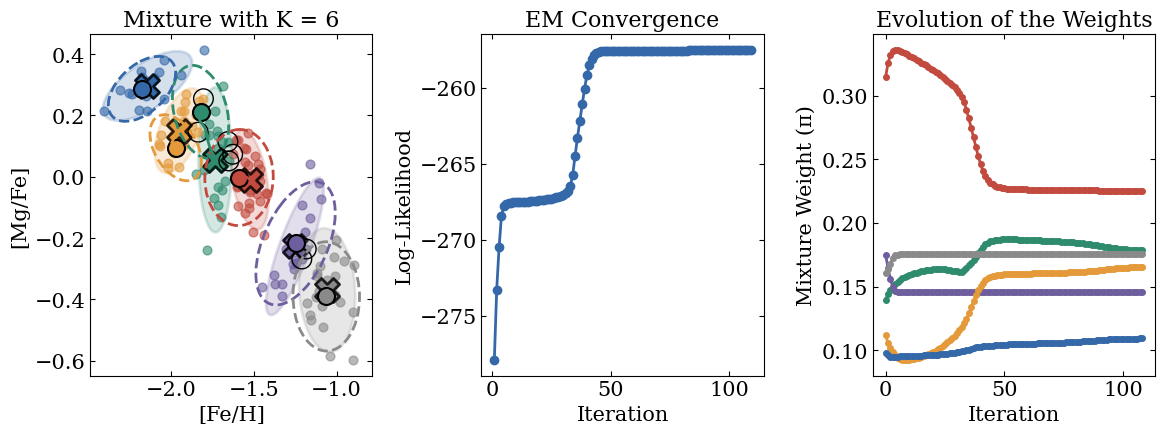

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11.9, 4.6))

# Left panel, the fitted mixture, the paths of the means and the ellipses of the start
component_colors = plot_gmm(axes[0], (weights, means, covariances, responsibilities), np.array([f'C{k}' for k in range(6)]))
start_weights, start_means, start_covariances = initialize_gmm(X_std, 6, init_method='kmeans++', random_state=14)
for i in range(6):
    # Path of mean i over the iterations, with a circle at the start
    path = np.array([m[i] for m in history['means']]) * std_X + mean_X
    axes[0].plot(path[:, 0], path[:, 1], '-', color=component_colors[i], linewidth=2)
    axes[0].scatter(path[0, 0], path[0, 1], c=[component_colors[i]], s=150, marker='o', edgecolor='black', linewidth=1.5)

    # Dashed ellipse of the starting component, in the original scale
    start_cov_orig = np.diag(std_X) @ start_covariances[i] @ np.diag(std_X)
    draw_ellipse(axes[0], path[0], start_cov_orig, 'none', component_colors[i], alpha=1, linestyle='--')
axes[0].set_title('Mixture with K = 6')

# Middle panel, the log-likelihood
axes[1].plot(range(1, len(history['log_likelihood']) + 1), history['log_likelihood'], 'o-', linewidth=2, markersize=6)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Log-Likelihood')
axes[1].set_title('EM Convergence')

# Right panel, the mixture weights at each iteration
weights_history = np.array(history['weights'])
for i in range(6):
    axes[2].plot(range(len(weights_history)), weights_history[:, i], 'o-', color=component_colors[i], linewidth=2, markersize=4)
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Mixture Weight (π)')
axes[2].set_title('Evolution of the Weights')

plt.tight_layout()
plt.show()

The log-likelihood rises quickly at first, stays nearly flat until about iteration 35, and gains again before iteration 50. The weights change at the same iterations. The component with the largest starting share of the stars gives part of it to its neighbors.

The components differ in weight and shape, which K-means does not model. The K-means clusters have similar sizes. The means move little. EM needs many more iterations than K-means.

## Model Selection for GMM: Information Criteria

The likelihood of the stars rises with every added component, so it cannot choose $K$. The information criteria correct the likelihood of the fit for the number of parameters $P$ with a penalty. They therefore replace a test set (Section 11.8). For $K$ components with full covariance matrices in $D$ dimensions, the number of parameters is $P = (K-1) + KD + KD(D+1)/2$ (Section 11.5). The terms count the weights, which sum to 1, the means and the symmetric covariance matrices. For $D = 2$ this gives $P = 6K - 1$.

The Bayesian information criterion (BIC) and the Akaike information criterion (AIC) are

$$\text{BIC} = -2\ln(\hat{L}) + P\ln(N),$$

$$\text{AIC} = -2\ln(\hat{L}) + 2P,$$

where $\hat{L}$ is the maximized likelihood and $N$ is the number of stars. Lower values are better. For our $N = 143$ stars, each parameter costs $\ln N = 4.96$ in BIC and 2 in AIC, so BIC tends to select fewer components. A component is worth adding only if it lowers $-2\ln(\hat{L})$ by more than its penalty. BIC approximates the evidence of the model, and AIC estimates how well the model predicts new stars (Section 11.8).

In [18]:
def compute_aic_bic(log_likelihood, n_samples, n_components, n_dimensions):
    """Return the AIC, the BIC and the number of free parameters of a GMM with full covariance matrices."""

    # Number of free parameters
    # Weights, K-1 because they sum to 1
    # Means, K*D
    # Covariances, K*D*(D+1)/2 because each matrix is symmetric
    n_parameters = ((n_components - 1) +
                    (n_components * n_dimensions) +
                    (n_components * n_dimensions * (n_dimensions + 1) // 2))

    # Information criteria
    aic = -2 * log_likelihood + 2 * n_parameters
    bic = -2 * log_likelihood + n_parameters * np.log(n_samples)

    return aic, bic, n_parameters

EM can end in a local maximum of the log-likelihood (Section 11.6). A component can also shrink onto a few stars, which raises $\ln L$ without describing a population. We therefore fit each $K$ from 1 to 8 from 20 starts. We drop the fits with a component of fewer than 6 stars, the number of free parameters of one component in two dimensions. We keep the fit with the highest $\ln L$ and compute its criteria.

In [19]:
# Fit K = 1 to 8 from 20 starts each. Keep the fit with the highest log-likelihood among the fits whose components all hold at least 6 stars
n_samples, n_dimensions = X_std.shape
ks = list(range(1, 9))
fits, aics, bics = {}, [], []

for k in ks:
    runs = [fit_gmm(X_std, k, init_method='kmeans++', random_state=seed) for seed in range(20)]
    runs = [run for run in runs if run[0].min() * n_samples >= 6]
    fits[k] = max(runs, key=lambda run: run[4])

    # Information criteria of the kept fit, for the plot
    aic, bic, _ = compute_aic_bic(fits[k][4], n_samples, k, n_dimensions)
    aics.append(aic)
    bics.append(bic)

We plot the two criteria and mark the lowest value of each.

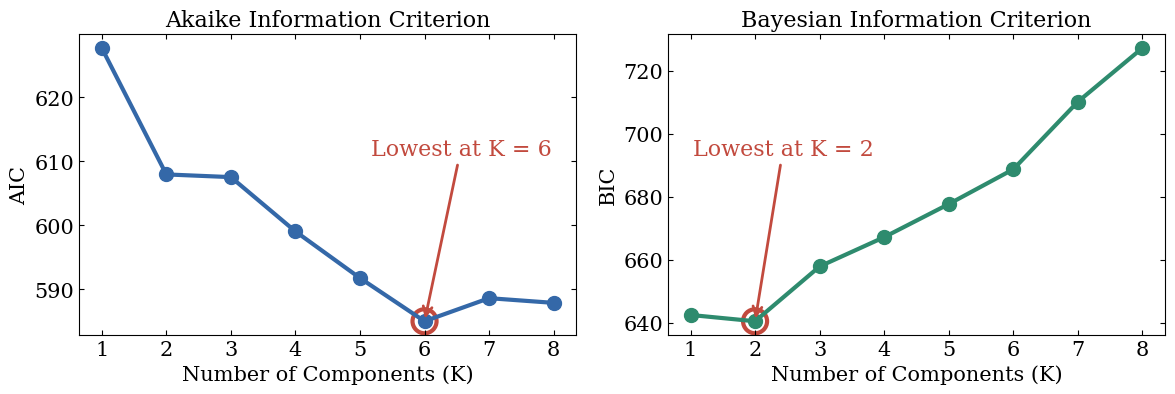

In [20]:
# Component numbers with the lowest AIC and the lowest BIC
k_aic = ks[int(np.argmin(aics))]
k_bic = ks[int(np.argmin(bics))]

# Plot the information criteria, and mark the lowest value of each
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, values, k_best, short, name, color, text_x, text_align in [
        (axes[0], aics, k_aic, 'AIC', 'Akaike Information Criterion', 'C0', 0.95, 'right'),
        (axes[1], bics, k_bic, 'BIC', 'Bayesian Information Criterion', 'C2', 0.05, 'left')]:
    ax.plot(ks, values, 'o-', linewidth=3, markersize=10, color=color)
    ax.set_xlabel('Number of Components (K)')
    ax.set_ylabel(short)
    ax.set_title(name)
    ax.set_xticks(ks)

    # Mark the lowest value
    ax.scatter(k_best, values[k_best - 1], s=300, facecolors='none', edgecolors='C3', linewidth=3)

    # Put the text in an empty part of the panel, in axes coordinates so that it stays inside
    ax.annotate(f'Lowest at K = {k_best}', xy=(k_best, values[k_best - 1]),
                xytext=(text_x, 0.62), textcoords='axes fraction', ha=text_align, va='center',
                arrowprops=dict(arrowstyle='->', color='C3', linewidth=2),
                fontsize=16, color='C3')

plt.tight_layout()
plt.show()

## Reading the Model Selection Results

BIC is lowest at $K = 2$, but only slightly below BIC at $K = 1$, so the data weakly prefer two components to one. AIC is lowest at $K = 6$ and stays nearly flat for larger $K$.

We plot the BIC model and the AIC model. The BIC model has $K = 2$, and the AIC model has $K = 6$. Rings mark the stars whose largest responsibility is below 0.8.

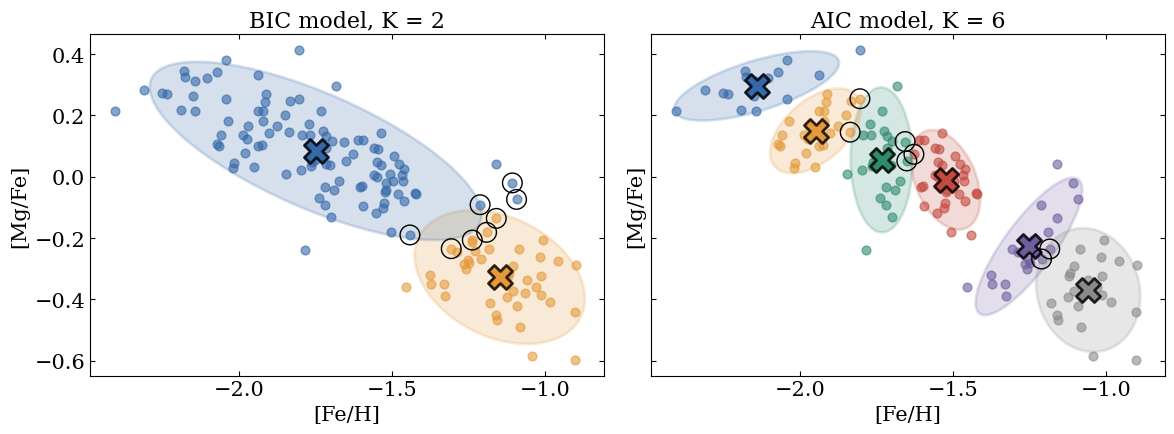

In [21]:
# Plot the BIC model and the AIC model in the original abundance plane
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, k_best, name in [(axes[0], k_bic, 'BIC'), (axes[1], k_aic, 'AIC')]:
    plot_gmm(ax, fits[k_best], np.array([f'C{k}' for k in range(k_best)]))
    ax.set_title(f'{name} model, K = {k_best}')

plt.tight_layout()
plt.show()

The BIC model splits the stars into a metal-poor group with a higher [Mg/Fe] and a metal-rich group with a lower [Mg/Fe]. The AIC model has more and smaller components along the same band.

The two criteria follow different views of model selection (Section 11.8). BIC treats the candidates as possible true models and approximates their evidence, so it prefers the simplest model that the sample supports. AIC treats every candidate as an approximation and estimates how well it predicts new stars, so it accepts more components when they improve the fit. Here the stars lie along a continuous band. The two broad components of the BIC model smooth over its shape, while the AIC components follow it more closely. BIC therefore suits a first look at the broad population structure, and AIC suits a detailed study of subpopulations.

The gaps between the groups are subtle, and the AIC mixture resolves them better than the broad BIC components. A mixture with AIC is therefore a good tool for groups of this kind.

## Summary

In this tutorial we looked for groups in the elemental abundances of stars in a dwarf galaxy. We built K-means and a Gaussian mixture model with the EM algorithm from scratch. Our main lessons follow.

1. **K-means.** K-means alternates between giving each point to its nearest center and moving each center to the mean of its points. Each step lowers the objective, so the algorithm ends in a local minimum. It assumes round clusters of equal weight and gives hard assignments.
2. **Initialization.** The result of K-means depends on its start, and so does the result of EM. Several starts, with the lowest inertia or the highest log-likelihood, reduce the risk of a poor local solution. K-means++ spreads the initial centers, and it can lower the mean inertia.
3. **Gaussian mixtures.** The EM algorithm fits a mixture with soft assignments. The E-step computes responsibilities, and the M-step sets the weights, means and covariance matrices to responsibility-weighted averages. Each component has its own weight and shape.
4. **The number of groups.** The inertia always falls as $K$ grows. The elbow is a first guess, and the science guides the choice. AIC and BIC penalize the number of parameters instead of using test data. BIC approximates the evidence and favors the simplest model, and AIC estimates the prediction of new data and allows more components, so they can disagree. A criterion needs a good fit for each $K$, so we use several starts and drop fits with tiny components.
5. **Reading the groups.** A group of objects can match a physical population, such as one burst of star formation. The number of groups from an algorithm or a criterion does not by itself count the populations, so we read it against the science.

K-means and Gaussian mixtures give a quantitative description of the groups in a sample. The mixture adds the probability that each object belongs to each group. A criterion and the science question together set how many groups to keep.